In [1]:
import pandas as pd

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")
test_df = pd.read_csv("test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (139780, 14)
Validation: (25676, 14)
Test: (39557, 14)


In [2]:
features = [
    "hr_mean",
    "hr_std",
    "hr_min",
    "hr_max",
    "hr_count",
    "motion_mean",
    "motion_std",
    "motion_min",
    "motion_max"
]

X_train = train_df[features]
X_val = val_df[features]
X_test = test_df[features]

y_train = train_df["stage_4"]
y_val = val_df["stage_4"]
y_test = test_df["stage_4"]

In [3]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nMissing values:")
print(X_train.isna().sum().sum())
print(X_val.isna().sum().sum())
print(X_test.isna().sum().sum())

display(X_train.head())

X_train: (139780, 9)
X_val: (25676, 9)
X_test: (39557, 9)

Training class distribution:
stage_4
0    14937
1    61750
2    26485
3    36608
Name: count, dtype: int64

Missing values:
0
0
0


,hr_mean,hr_std,hr_min,hr_max,hr_count,motion_mean,motion_std,motion_min,motion_max
0,64.333333,1.966384,63.0,68.0,6,1.005263,0.083865,0.597759,1.707987
1,69.333333,1.527525,68.0,71.0,3,1.016832,0.136838,0.334249,2.314065
2,74.000000,1.000000,73.0,75.0,3,1.048849,0.246704,0.263571,3.822546
3,76.666667,3.214550,73.0,79.0,3,1.052265,0.263902,0.115942,3.001449
4,72.000000,0.000000,72.0,72.0,3,1.032463,0.199030,0.374140,2.522472


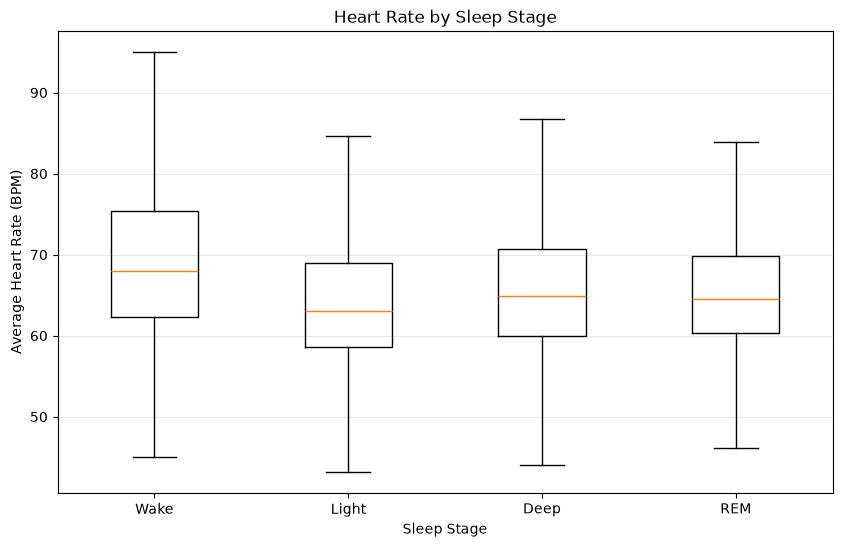

In [4]:
import matplotlib.pyplot as plt

stages = ["Wake", "Light", "Deep", "REM"]

hr_data = [
    train_df[train_df["stage_4"] == i]["hr_mean"]
    for i in range(4)
]

plt.figure(figsize=(10, 6))

plt.boxplot(hr_data, tick_labels=stages, showfliers=False)

plt.title("Heart Rate by Sleep Stage")
plt.xlabel("Sleep Stage")
plt.ylabel("Average Heart Rate (BPM)")
plt.grid(axis="y", alpha=0.3)

plt.show()

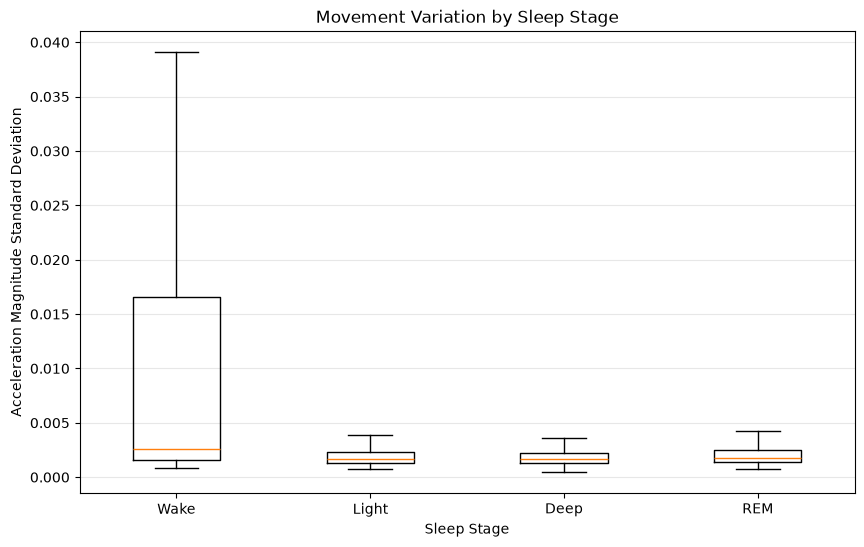

In [5]:
motion_data = [
    train_df[train_df["stage_4"] == i]["motion_std"]
    for i in range(4)
]

plt.figure(figsize=(10, 6))

plt.boxplot(motion_data, tick_labels=stages, showfliers=False)

plt.title("Movement Variation by Sleep Stage")
plt.xlabel("Sleep Stage")
plt.ylabel("Acceleration Magnitude Standard Deviation")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [6]:
train_df.groupby("stage_4")["motion_std"].agg(
    ["mean", "median", "std"]
).round(4)

,mean,median,std
stage_4,,,
0,0.0249,0.0026,0.0520
1,0.0057,0.0017,0.0185
2,0.0042,0.0017,0.0146
3,0.0073,0.0018,0.0224


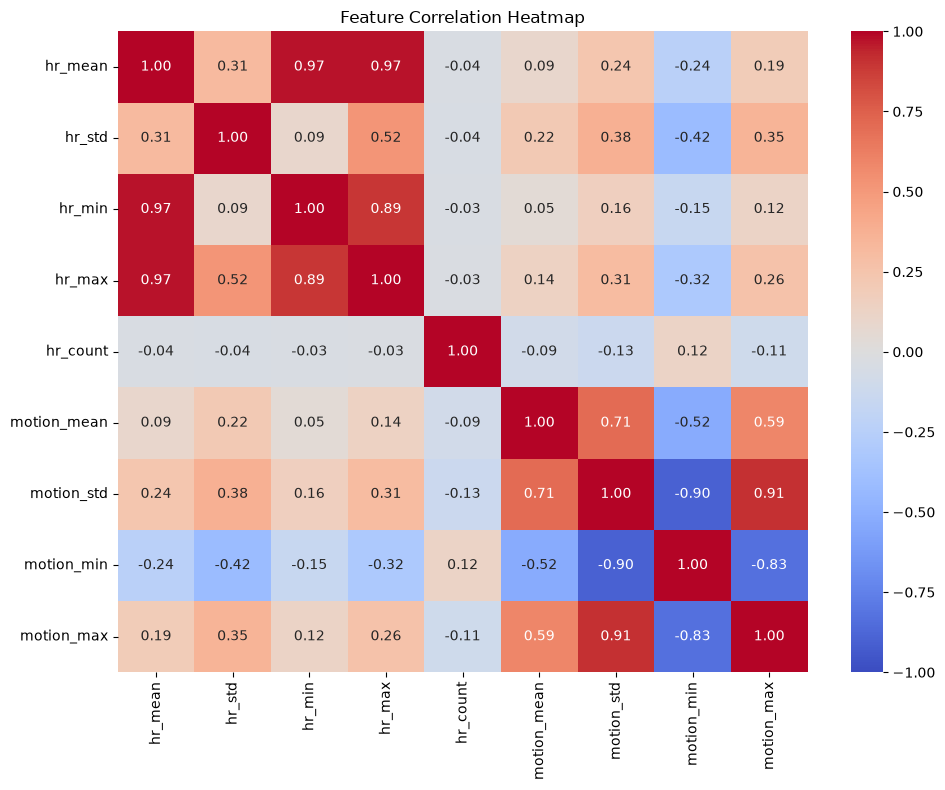

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = train_df[features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

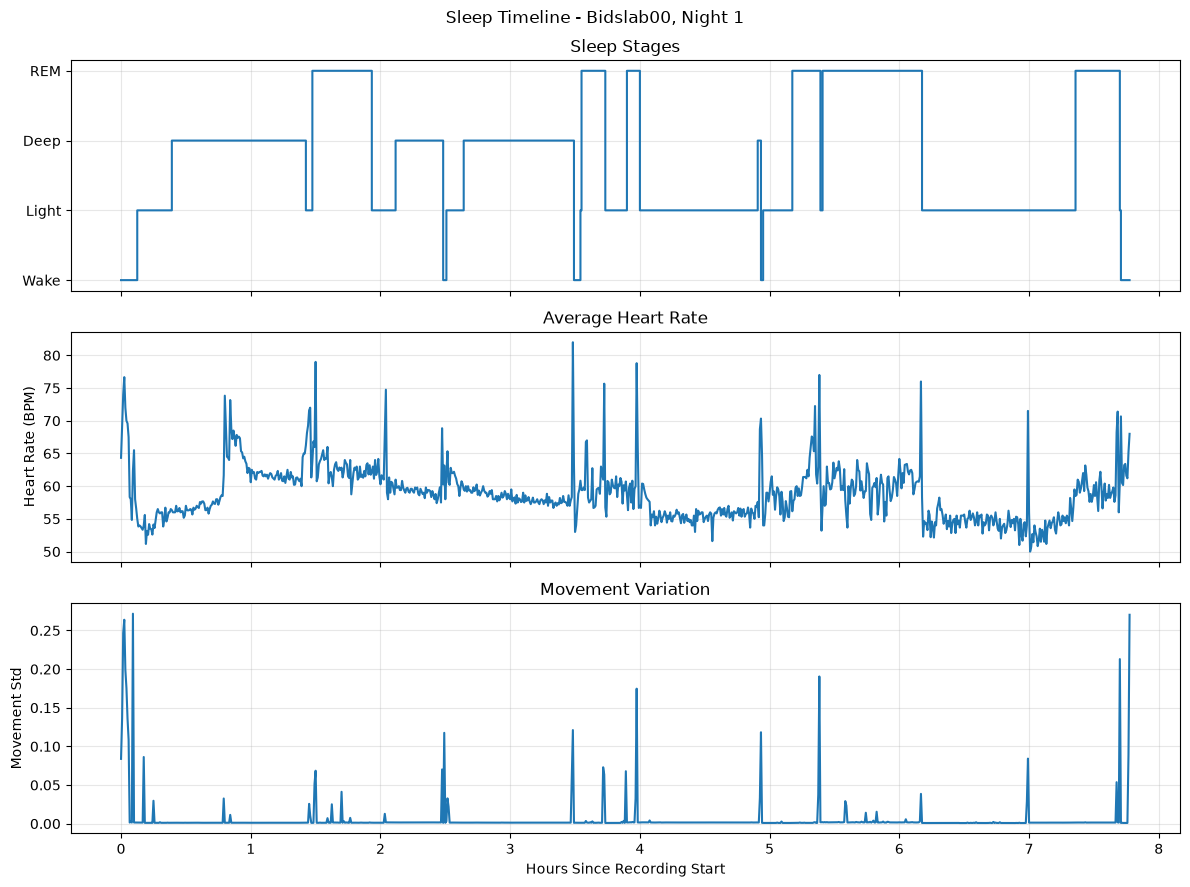

In [8]:
# Select one recording night
person = train_df["person"].iloc[0]

night = train_df.loc[
    train_df["person"] == person, "night"
].iloc[0]

night_df = train_df[
    (train_df["person"] == person) &
    (train_df["night"] == night)
].sort_values("epoch").copy()

# 120 epochs = 1 hour
night_df["hours"] = night_df["epoch"] / 120

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Sleep stages
axes[0].step(night_df["hours"], night_df["stage_4"], where="post")
axes[0].set_yticks([0, 1, 2, 3])
axes[0].set_yticklabels(["Wake", "Light", "Deep", "REM"])
axes[0].set_title("Sleep Stages")

# Heart rate
axes[1].plot(night_df["hours"], night_df["hr_mean"])
axes[1].set_ylabel("Heart Rate (BPM)")
axes[1].set_title("Average Heart Rate")

# Movement
axes[2].plot(night_df["hours"], night_df["motion_std"])
axes[2].set_ylabel("Movement Std")
axes[2].set_title("Movement Variation")
axes[2].set_xlabel("Hours Since Recording Start")

for ax in axes:
    ax.grid(alpha=0.3)

plt.suptitle(f"Sleep Timeline - {person}, Night {night}")
plt.tight_layout()
plt.show()